# Phase 7b: Monitoring, improved and re-tested on fresh data

Phase 7's drift test raised false alarms on clean data. Phase 7b replaces it with a wear-adjusted test, fixes the rule before looking, and tests it on NASA's FD002 and FD004, which nothing had seen. Full results: `docs/MONITORING_7B.md`.

## Concepts in plain words

- **Residual:** what a sensor reads minus what it should read for an engine of that age and predicted remaining life.
- **Persistence:** a sensor counts as drifted only if it drifts in 2 of the last 3 runs, unless the evidence is overwhelming (a sudden fault).
- **Pre-registration:** writing down the rule and the pass marks before the test data is touched.
- **Censoring:** a serviced engine never fails, so we never learn its true remaining life.

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / 'docs' / 'figures'
OUT = ROOT / 'pipeline' / 'phase7b'
chk = json.loads((OUT / 'checks.json').read_text())
fs = json.loads((OUT / 'fault_suite.json').read_text())
pd.DataFrame(chk['C1']).T

,runs,flagged,rate,kind
FD002 synchronized,554,0,0.0,confirmation
FD004 synchronized,554,108,0.194946,confirmation
FD002 staggered,667,6,0.008996,confirmation
FD004 staggered,667,93,0.13943,confirmation
FD001 synchronized,484,0,0.0,post hoc
FD003 synchronized,484,0,0.0,post hoc
FD001 staggered,560,0,0.0,post hoc
FD003 staggered,560,0,0.0,post hoc


## Clean-run flags over the replay

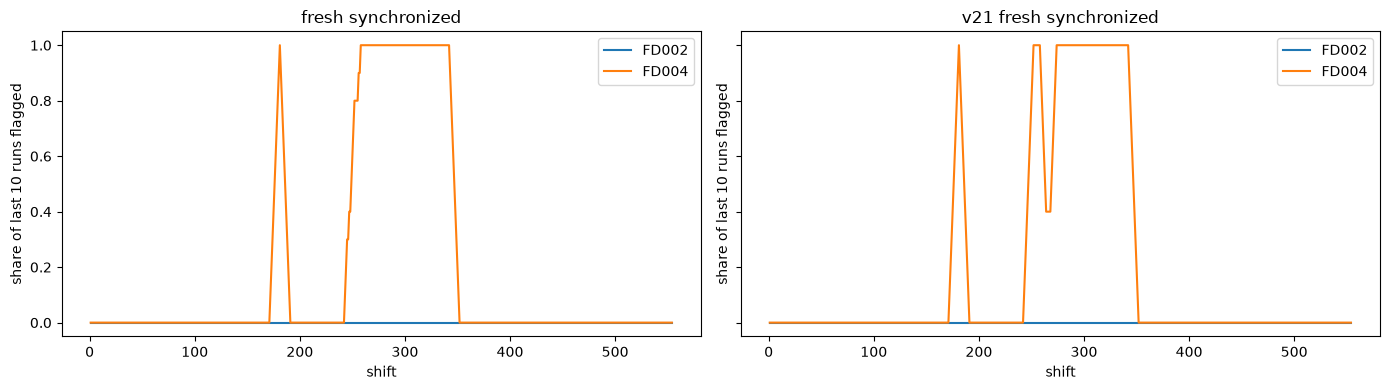

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, sc in zip(axes, ['fresh_synchronized', 'v21_fresh_synchronized']):
    h = pd.read_csv(OUT / sc / 'phase7_health.csv')
    for ds, g in h.groupby('dataset'):
        ax.plot(g['shift'], g.needs_retraining.astype(int).rolling(10, min_periods=1).mean(), label=ds)
    ax.set(title=sc.replace('_', ' '), xlabel='shift', ylabel='share of last 10 runs flagged'); ax.legend()
fig.tight_layout(); fig.savefig(FIG / 'phase7b_flags.png', dpi=150, bbox_inches='tight')

## Fault suite

In [3]:
pd.DataFrame({ds: {k: f"{v['detected']}/{v['testable']}" for k, v in fs[ds].items() if isinstance(v, dict) and 'rows' in v}
              for ds in ('FD002', 'FD004')})

,FD002,FD004
step,84/84,84/84
ramp,84/84,84/84
stuck,84/84,84/84
noise,81/84,77/84
dropout,0/84,5/84


## Closed loop

In [4]:
pd.DataFrame(chk['closed_loop']).T

,engines,failed_labelled,censored,censored_certainly_not_miss,censored_undetermined,miss_rate_from_labels_only,miss_rate_bounds_all_engines,true_miss_rate_same_forecasts
FD002,259,37,222,15,207,0.243243,"[0.03474903474903475, 0.833976833976834]",0.03861
FD004,248,5,243,19,224,1.0,"[0.020161290322580645, 0.9233870967741935]",0.044355


## What the results say

1. **Fixed before testing, then tested on unseen fleets.** Criteria, rule and fresh-fleet settings were committed before any FD002/FD004 test replay.
2. **C1 (clean-run flags <= 5%) passes on FD002** (0.0% / 0.9%) **and fails on FD004** (19.5% / 13.9%). On FD001/FD003 (post hoc) the new rule raised 0 and 0 flags, where Phase 7's rule had 11.6% false alarms.
3. **C2-C4 pass on both fresh fleets:** one +5% batch sets the flag (as 'sensor fault suspected'); +1 sd steps are caught within 10 shifts in 100% / 100% of injections, ramps in 100% / 100%. Dropouts are invisible to drift by design.
4. **A real defect was found and fixed, but it was not FD004's cause.** The spread model went negative in sparse corners (975 FD004 readings with |z| > 20; 0 after the log-scale fix). Re-scored post hoc with the fix, FD004 still flags 18.8% of synchronized runs. Its flagged pattern correlates +0.77 / -0.82 with the two fault-mode signatures: likely a fault-mode mixture, not proven.
5. **Closed loop:** when services are carried out, only 37 of 259 FD002 engines ever produce a failure label, and the labels-only miss rate reads 24% against a true 3.9%. Censored engines give bounds that contain the truth but are too wide to act on: a deployment needs inspection labels or a control group.

## Why we did these tasks

| # | Task | Why we did it | What we learned | What it changes next |
| --- | --- | --- | --- | --- |
| 1 | Success criteria and rule committed before any fresh replay | A rule judged on data that shaped it proves nothing | The criteria made a mixed result impossible to hide | Any further change needs data nobody has seen |
| 2 | Wear-adjusted residuals instead of raw readings | Phase 7 mistook healthy survivors for drift | On FD001/FD003 and FD002 the false alarms vanished | Drift tests must condition on the state of the machine |
| 3 | Cross-fitted 60-engine calibration fleets | 20-engine fleets could not reproduce the failure | A calibration set must be able to show the problem it is meant to fix | Check calibration data against the known failure first |
| 4 | Fresh confirmation on FD002 and FD004 | The only honest test of a fix | FD002 passed; FD004 failed | Fault modes need their own expected levels |
| 5 | Root-cause before re-scoring | A failure is information | A real defect existed but was not the cause; my first explanation was wrong and is corrected | Test an explanation with the fix before believing it |
| 6 | Fault suite through a mirror proven equal to the flow | 840 injections would take days in the real flow | Steps and ramps are caught within 2-8 shifts | Fleet-wide faults are covered; single-engine faults are not |
| 7 | Closed loop with censoring bounds | Real maintenance hides the labels monitoring needs | Labels-only monitoring is badly biased once the model acts | Plan inspection labels or a control group into the process |
